# HVG Selection

- **Purpose:** Compare candidate highly variable gene selections and their effect on the cell line and tumor representations.
- **Inputs:** Raw and processed datasets under `data/`.
- **Outputs:** Summaries and plots shown in the notebook.
- **Status:** Exploratory; the final HPO grid uses 3,000, 5,000, and 10,000 HVGs.


## Overview
Should not rerun this code. I have since deleted the datasets of the complete gene set datasets `cellline_CRC.h5ad` and `tumor_epiT.h5ad`. It seems to make little sense to even consider the complete gene set of the tumor data as we have ~30k complete genes in the celllines and >40k complete genes in the tumor data. 

I will keep this notebook for now should i need to circle back to the HVG selection. Maybe there will be use case for hard adding the cell line HVGs of the intersection genes and maybe manually checking the complete HVGs of the cell lines that are not part of the intersections. Should there be a gene_name mismatch from the cell line side (cell line dataset has no gene_id and gene annotation file gene_id does not match gene_name as it matches to the tumor genes) it could be benefical to add these few genes. 

As a reminder one such gene that is part of the mismatch: ACRC/GCNA and it (and other genes) could be part of HVGs from the cell lines (and tumors) that we lose.

In [1]:
import pandas as pd
import scanpy as sc
import anndata as ad
import numpy as np
import os

from scipy import sparse

import h5py

In [2]:
DATA_DIR = os.path.join("..", "..", "data")
PROCESSED_DIR = os.path.join(DATA_DIR, "processed")

CL_full_path = os.path.join(PROCESSED_DIR, "cellline_CRC.h5ad")
tumor_full_path = os.path.join(PROCESSED_DIR, "tumor_epiT.h5ad")

tumor_pp_path = os.path.join(PROCESSED_DIR, "pp_tumor.h5ad")
CL_pp_path = os.path.join(PROCESSED_DIR, "pp_cell_line.h5ad")

In [3]:
# mainly added for the mt/ribo markers -> might be interesting to remove mt from HVG
def qc_metrics(adata):
    adata.var["mt"] = adata.var_names.str.startswith(("MT-"))
    adata.var["ribo"] = adata.var_names.str.startswith(("RPL", "RPS"))

    sc.pp.calculate_qc_metrics(
        adata, qc_vars= ["mt", "ribo"],
        percent_top=(50, 100, 200, 500), log1p=True, inplace=True
    )
    return adata

# Cell line

## Cell line - full genes

In [4]:
adata_CL_full = ad.read_h5ad(CL_full_path)
adata_CL_full

AnnData object with n_obs × n_vars = 2256 × 30314
    obs: 'cell_id', 'pool_id', 'cell_line'
    var: 'gene_symbol', 'gene_id'

In [5]:
adata_CL_full.layers["counts"] = adata_CL_full.X
adata_CL_full = qc_metrics(adata_CL_full)

In [6]:
sc.pp.highly_variable_genes(
    adata_CL_full,
    n_top_genes=5000,
    subset=False,
    layer="counts",
    flavor="seurat_v3",
    batch_key="pool_id"
)

highly_variable_nbatches
0    16662
1     5340
2     3691
3     2405
4     1307
5      619
6      290
Name: count, dtype: int64

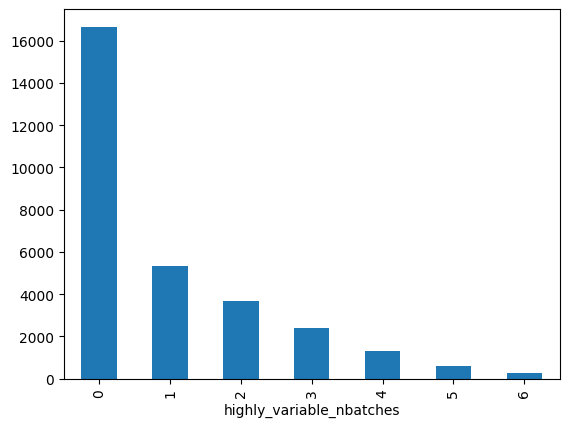

In [7]:
n_batches = adata_CL_full.var["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

## Cell line - intersected genes

In [8]:
adata_CL_inter = ad.read_h5ad(CL_pp_path)
adata_CL_inter

AnnData object with n_obs × n_vars = 2162 × 28617
    obs: 'cell_id', 'pool_id', 'cell_line', 'mmr_status', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'outlier_qc', 'n_genes', 'doublet_score', 'predicted_doublet', 'outlier', 'chemistry'
    var: 'gene_symbol', 'gene_id', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: 'counts'

In [9]:
sc.pp.highly_variable_genes(
    adata_CL_inter,
    n_top_genes=5000,
    subset=False,
    layer="counts",
    flavor="seurat_v3",
    batch_key="pool_id"
)

highly_variable_nbatches
0    14859
1     5368
2     3750
3     2501
4     1305
5      595
6      239
Name: count, dtype: int64

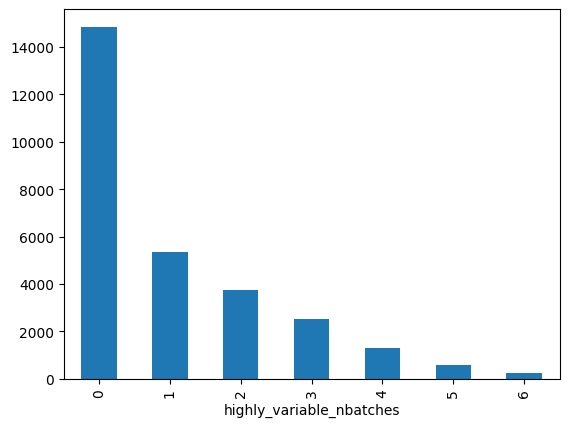

In [10]:
n_batches = adata_CL_inter.var["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

## Comparison

In [11]:
full_hvg = adata_CL_full.var

# lost HVGs
full_hvg_strong = full_hvg[full_hvg["highly_variable"]]
lost_hvg = full_hvg_strong.index.difference(adata_CL_inter.var_names)

# lost genes with >=2 nbatches from highly_variable_genes
full_2nbatches = full_hvg[full_hvg["highly_variable_nbatches"] >= 2]
lost_2nbatches = full_2nbatches.index.difference(adata_CL_inter.var_names)

# lost genes with >=1 nbatches from highly_variable_genes
full_1nbatches = full_hvg[full_hvg["highly_variable_nbatches"] >= 1]
lost_1nbatches = full_1nbatches.index.difference(adata_CL_inter.var_names)

In [12]:
print(f"# of Cell Line HVGs not in intersection: {len(lost_hvg)}")
for gene in lost_hvg[:10]:
    print(gene)

# of Cell Line HVGs not in intersection: 148
ACRC
AIM1L
AL354822.1
AL592183.1
AP000769.1
APITD1
C10orf131
C10orf54
C19orf48
C1QTNF9B-AS1


In [13]:
print(f"# of Cell Line Genes with >=2 nbatches not in intersection: {len(lost_2nbatches)}")
for gene in lost_2nbatches[:10]:
    print(gene)

# of Cell Line Genes with >=2 nbatches not in intersection: 216
ABHD17C
AC011043.1
AIM1L
AL589743.1
AL592183.1
APITD1
ASB16-AS1
ASUN
ATP5EP2
BCYRN1


In [14]:
print(f"# of Cell Line Genes with >=1 nbatches not in intersection: {len(lost_1nbatches)}")
for gene in lost_1nbatches[:10]:
    print(gene)

# of Cell Line Genes with >=1 nbatches not in intersection: 427
A2M-AS1
ABHD17C
AC011043.1
AC109829.1
AC133528.2
ACRC
ACTA2-AS1
ADM5
ADPGK-AS1
AGBL5-AS1


# Tumor

## Tumor - full genes

In [15]:
adata_tumor_full = ad.read_h5ad(tumor_full_path)
adata_tumor_inter = ad.read_h5ad(tumor_pp_path)

In [16]:
adata_tumor_full.var_names = adata_tumor_full.var.gene_symbol.astype(str)
adata_tumor_full.obs["batch"] = adata_tumor_inter.obs["batch"]
adata_tumor_full

AnnData object with n_obs × n_vars = 108131 × 43085
    obs: 'cell_id', 'donor_id', 'biosample_id', 'mmr_status', 'chemistry', 'label', 'cell_type', 'batch'
    var: 'gene_symbol', 'gene_id'

In [17]:
#sanity check - obs_names in correct order
(adata_tumor_full.obs_names == adata_tumor_inter.obs_names).sum()

np.int64(108131)

In [18]:
adata_tumor_full.layers["counts"] = adata_tumor_full.X
adata_tumor_full = qc_metrics(adata_tumor_full)

In [19]:
v3_mask = np.array([c in ["v3"] for c in adata_tumor_full.obs["chemistry"]])

adata_tumor_full_v2 = adata_tumor_full[~v3_mask].copy()
adata_tumor_full_v3 = adata_tumor_full[v3_mask].copy()

/mnt/bigdisk/markus/miniconda3/envs/scvi-env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [20]:
sc.pp.highly_variable_genes(
    adata_tumor_full,
    n_top_genes=5000,
    subset=False,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch"
)

sc.pp.highly_variable_genes(
    adata_tumor_full_v2,
    n_top_genes=5000,
    subset=False,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch"
)

sc.pp.highly_variable_genes(
    adata_tumor_full_v3,
    n_top_genes=5000,
    subset=False,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch"
)

In [21]:
hvg_v2_full = adata_tumor_full_v2.var
hvg_v3_full = adata_tumor_full_v3.var
hvg_combined_full = adata_tumor_full.var

### nbatches

In the following 3 cells we can see that using `highly_variable_genes` leads to multiple genes being included even tough they are highly variable in 0 batches. Another interesting detail is that HVG leads to more than 5k genes with all the tumor genes while the intersection leads to 5k.

Seurat_v3 behaviour here is weird in my opinion but i guess the `n_top_genes` with 5k is pretty big for our data with ~60batches in the v2/combined case. Seurat_v3 computes the hvg per batch and then selects genes based on these results. But then it does not select just the genes that are HVG in the most batches but this excerpt discusses the heuristic: 

> Only if batch_key is not None, the two flavors differ: For flavor='seurat_v3', genes are first sorted by the median (across batches) rank, with ties broken by the number of batches a gene is a HVG. For flavor='seurat_v3_paper', genes are first sorted by the number of batches a gene is a HVG, with ties broken by the median (across batches) rank.

#### Highly variable genes and their nbatches

In [22]:
hvg_v2_full[hvg_v2_full["highly_variable"]]["highly_variable_nbatches"].value_counts()

highly_variable_nbatches
0     1331
1      807
3      404
2      373
4      262
44     235
5      220
43     167
6      154
7      143
8      135
42     112
41     107
40     104
38     101
39     101
11      99
9       90
13      76
37      71
36      71
10      69
14      67
12      66
34      66
15      65
33      59
35      59
31      59
16      55
26      54
28      54
29      51
24      50
19      48
22      48
17      47
25      47
23      47
32      45
21      45
27      44
18      44
30      44
20      42
Name: count, dtype: int64

In [23]:
hvg_v3_full[hvg_v3_full["highly_variable"]]["highly_variable_nbatches"].value_counts()

highly_variable_nbatches
1     1303
0     1275
21     498
2      469
3      335
20     263
4      229
5      204
19     178
18     150
16     143
17     141
7      132
6      127
9      120
13     118
14     116
15     106
10     105
12     103
8       99
11      93
Name: count, dtype: int64

In [24]:
# only 20 
hvg_combined_full[hvg_combined_full["highly_variable"]]["highly_variable_nbatches"].value_counts()[:20]

highly_variable_nbatches
0     1224
1      733
3      311
2      308
4      240
5      207
65     205
6      155
7      129
64     110
63     103
8       96
9       93
61      88
11      87
10      83
62      76
12      74
60      71
14      70
Name: count, dtype: int64

#### Analysis only nbatches

######## v2 ########
# of HVG:  6438
# of HVG with >=1 nbatches:  23109
# of HVG with >=10 nbatches:  7301
# of HVG with >=15 nbatches:  5035
# of HVG with >=20 nbatches:  3681


highly_variable_nbatches
0     19976
1      4183
2      2824
3      2057
4      1703
5      1430
6      1161
7      1005
8       784
9       661
10      560
11      518
12      441
13      388
14      359
15      333
16      279
18      250
19      247
17      245
44      235
20      223
23      202
22      199
21      192
24      180
25      172
43      167
26      164
29      150
27      145
28      136
32      129
31      129
33      125
30      122
34      121
39      118
36      117
38      116
40      113
41      113
42      113
35      102
37       98
Name: count, dtype: int64

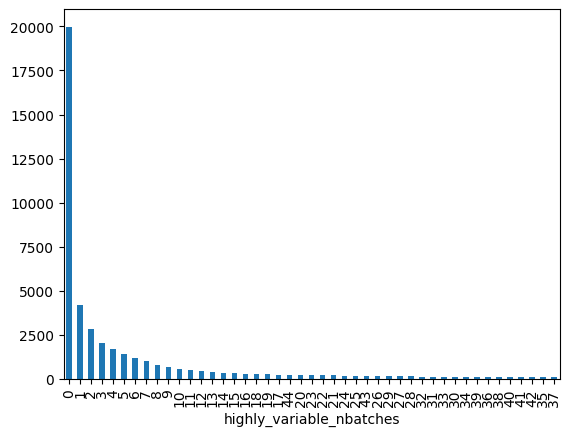

In [25]:
num_1_nbatches = hvg_v2_full[hvg_v2_full["highly_variable_nbatches"] >= 1].shape[0]
num_10_nbatches = hvg_v2_full[hvg_v2_full["highly_variable_nbatches"] >= 10].shape[0]
num_15_nbatches = hvg_v2_full[hvg_v2_full["highly_variable_nbatches"] >= 15].shape[0]
num_20_nbatches = hvg_v2_full[hvg_v2_full["highly_variable_nbatches"] >= 20].shape[0]

print("######## v2 ########")
print(f"# of HVG: ", adata_tumor_full_v2.var.highly_variable.sum())
print(f"# of HVG with >=1 nbatches: ", num_1_nbatches)
print(f"# of HVG with >=10 nbatches: ", num_10_nbatches)
print(f"# of HVG with >=15 nbatches: ", num_15_nbatches)
print(f"# of HVG with >=20 nbatches: ", num_20_nbatches)

n_batches = hvg_v2_full["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

######## v3 ########
# of HVG:  6307
# of HVG with >=1 nbatches:  18286
# of HVG with >=10 nbatches:  3997
# of HVG with >=15 nbatches:  2225
# of HVG with >=20 nbatches:  823


highly_variable_nbatches
0     24799
1      5128
2      2826
3      1742
4      1263
5       935
6       764
7       608
8       526
21      513
9       497
10      418
11      377
13      345
12      343
20      310
17      300
16      295
14      289
15      272
19      269
18      266
Name: count, dtype: int64

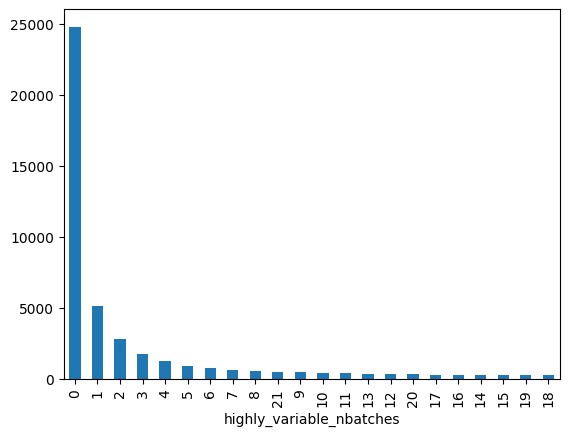

In [26]:
num_1_nbatches = hvg_v3_full[hvg_v3_full["highly_variable_nbatches"] >= 1].shape[0]
num_10_nbatches = hvg_v3_full[hvg_v3_full["highly_variable_nbatches"] >= 10].shape[0]
num_15_nbatches = hvg_v3_full[hvg_v3_full["highly_variable_nbatches"] >= 15].shape[0]
num_20_nbatches = hvg_v3_full[hvg_v3_full["highly_variable_nbatches"] >= 20].shape[0]

print("######## v3 ########")
print(f"# of HVG: ", adata_tumor_full_v3.var.highly_variable.sum())
print(f"# of HVG with >=1 nbatches: ", num_1_nbatches)
print(f"# of HVG with >=10 nbatches: ", num_10_nbatches)
print(f"# of HVG with >=15 nbatches: ", num_15_nbatches)
print(f"# of HVG with >=20 nbatches: ", num_20_nbatches)

n_batches = hvg_v3_full["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

######## combined v2+v3 ########
# of HVG:  6343
# of HVG with >=1 nbatches:  24488
# of HVG with >=10 nbatches:  9572
# of HVG with >=15 nbatches:  7039
# of HVG with >=20 nbatches:  5546
# of HVG with >=25 nbatches:  4449
# of HVG with >=30 nbatches:  3606


highly_variable_nbatches
0     18597
1      3570
2      2430
3      1952
4      1624
      ...  
54       70
52       70
45       69
55       67
49       67
Name: count, Length: 66, dtype: int64

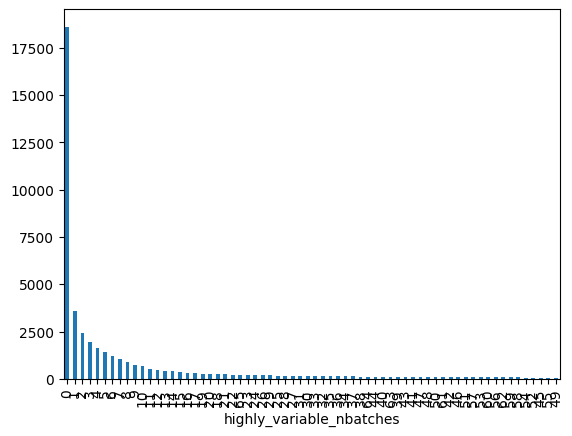

In [27]:
num_1_nbatches = hvg_combined_full[hvg_combined_full["highly_variable_nbatches"] >= 1].shape[0]
num_10_nbatches = hvg_combined_full[hvg_combined_full["highly_variable_nbatches"] >= 10].shape[0]
num_15_nbatches = hvg_combined_full[hvg_combined_full["highly_variable_nbatches"] >= 15].shape[0]
num_20_nbatches = hvg_combined_full[hvg_combined_full["highly_variable_nbatches"] >= 20].shape[0]
num_25_nbatches = hvg_combined_full[hvg_combined_full["highly_variable_nbatches"] >= 25].shape[0]
num_30_nbatches = hvg_combined_full[hvg_combined_full["highly_variable_nbatches"] >= 30].shape[0]

print("######## combined v2+v3 ########")
print(f"# of HVG: ", adata_tumor_full.var.highly_variable.sum())
print(f"# of HVG with >=1 nbatches: ", num_1_nbatches)
print(f"# of HVG with >=10 nbatches: ", num_10_nbatches)
print(f"# of HVG with >=15 nbatches: ", num_15_nbatches)
print(f"# of HVG with >=20 nbatches: ", num_20_nbatches)
print(f"# of HVG with >=25 nbatches: ", num_25_nbatches)
print(f"# of HVG with >=30 nbatches: ", num_30_nbatches)

n_batches = hvg_combined_full["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

In [28]:
hvg_combined_full["highly_variable_nbatches"].value_counts()[:25]

highly_variable_nbatches
0     18597
1      3570
2      2430
3      1952
4      1624
5      1427
6      1205
7      1061
8       896
9       751
10      653
11      545
12      492
13      427
14      416
15      357
16      325
17      289
19      263
20      262
18      259
21      239
22      206
65      205
23      196
Name: count, dtype: int64

## Tumor - intersected genes
Reading the adata in the section above as we need the intersection adata for some metadata batch key.

In [29]:
adata_tumor_inter_v2 = adata_tumor_inter[~v3_mask].copy()
adata_tumor_inter_v3 = adata_tumor_inter[v3_mask].copy()

In [30]:
sc.pp.highly_variable_genes(
    adata_tumor_inter,
    n_top_genes=5000,
    subset=False,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch"
)

sc.pp.highly_variable_genes(
    adata_tumor_inter_v2,
    n_top_genes=5000,
    subset=False,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch"
)

sc.pp.highly_variable_genes(
    adata_tumor_inter_v3,
    n_top_genes=5000,
    subset=False,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch"
)

In [31]:
hvg_v2_inter = adata_tumor_inter_v2.var
hvg_v3_inter = adata_tumor_inter_v3.var
hvg_combined_inter = adata_tumor_inter.var

### nbatches

#### Highly variable genes and their nbatches

In [32]:
hvg_v2_inter[hvg_v2_inter["highly_variable"]]["highly_variable_nbatches"].value_counts()

highly_variable_nbatches
1     275
44    236
5     216
3     205
2     174
4     171
43    157
6     152
7     148
8     133
9     129
12    117
40    117
42    114
39    111
13    110
34    103
15    103
41    103
38    102
14    102
33    100
36     99
11     95
32     95
10     94
37     94
35     91
16     90
30     85
28     83
17     82
23     82
27     81
29     79
26     79
24     78
21     78
20     76
25     75
31     74
19     73
18     71
22     68
Name: count, dtype: int64

In [33]:
hvg_v3_inter[hvg_v3_inter["highly_variable"]]["highly_variable_nbatches"].value_counts()

highly_variable_nbatches
1     902
21    518
2     383
3     329
20    277
4     243
5     219
19    215
18    202
6     176
17    167
7     160
15    153
16    145
14    143
9     136
13    134
10    132
8     130
12    118
11    118
Name: count, dtype: int64

In [34]:
# only 20 
hvg_combined_inter[hvg_combined_inter["highly_variable"]]["highly_variable_nbatches"].value_counts()[:20]

highly_variable_nbatches
65    208
1     202
5     158
3     157
7     135
4     122
8     115
2     114
6     113
64    112
9      94
63     92
11     92
61     91
12     89
17     85
14     84
19     82
18     81
10     81
Name: count, dtype: int64

#### Analysis only nbatches

######## v2 ########
# of HVG:  6438
# of Genes with >=1 nbatches:  22054
# of Genes with >=10 nbatches:  7217
# of Genes with >=15 nbatches:  4932
# of Genes with >=20 nbatches:  3603


highly_variable_nbatches
0     6563
1     2726
2     2366
3     2149
4     1898
5     1724
6     1363
7     1058
8      844
9      709
10     578
11     496
12     457
13     383
14     371
15     317
16     285
17     258
19     241
44     236
18     228
20     215
21     205
23     194
22     188
24     176
25     173
43     157
26     154
27     146
30     139
28     135
33     131
32     130
29     125
34     120
40     117
42     114
39     114
36     111
31     108
35     105
37     104
38     103
41     103
Name: count, dtype: int64

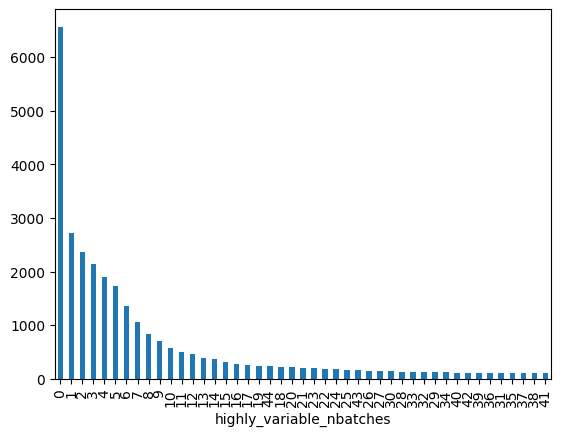

In [35]:
num_1_nbatches = hvg_v2_inter[hvg_v2_inter["highly_variable_nbatches"] >= 1].shape[0]
num_10_nbatches = hvg_v2_inter[hvg_v2_inter["highly_variable_nbatches"] >= 10].shape[0]
num_15_nbatches = hvg_v2_inter[hvg_v2_inter["highly_variable_nbatches"] >= 15].shape[0]
num_20_nbatches = hvg_v2_inter[hvg_v2_inter["highly_variable_nbatches"] >= 20].shape[0]

print("######## v2 ########")
print(f"# of HVG: ", adata_tumor_full_v2.var.highly_variable.sum())
print(f"# of Genes with >=1 nbatches: ", num_1_nbatches)
print(f"# of Genes with >=10 nbatches: ", num_10_nbatches)
print(f"# of Genes with >=15 nbatches: ", num_15_nbatches)
print(f"# of Genes with >=20 nbatches: ", num_20_nbatches)

n_batches = hvg_v2_inter["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

######## v3 ########
# of HVG:  6307
# of Genes with >=1 nbatches:  18294
# of Genes with >=10 nbatches:  4015
# of Genes with >=15 nbatches:  2261
# of Genes with >=20 nbatches:  825


highly_variable_nbatches
0     10323
1      5092
2      2915
3      1794
4      1222
5       924
6       737
7       636
21      524
8       489
9       470
10      419
11      365
12      351
13      323
18      305
20      301
15      300
14      296
17      289
19      271
16      271
Name: count, dtype: int64

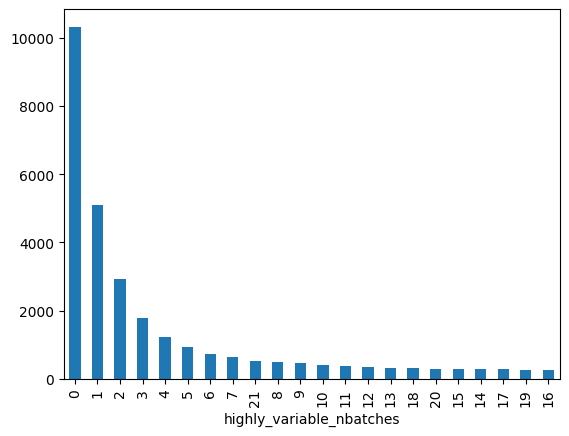

In [36]:
num_1_nbatches = hvg_v3_inter[hvg_v3_inter["highly_variable_nbatches"] >= 1].shape[0]
num_10_nbatches = hvg_v3_inter[hvg_v3_inter["highly_variable_nbatches"] >= 10].shape[0]
num_15_nbatches = hvg_v3_inter[hvg_v3_inter["highly_variable_nbatches"] >= 15].shape[0]
num_20_nbatches = hvg_v3_inter[hvg_v3_inter["highly_variable_nbatches"] >= 20].shape[0]

print("######## v3 ########")
print(f"# of HVG: ", adata_tumor_full_v3.var.highly_variable.sum())
print(f"# of Genes with >=1 nbatches: ", num_1_nbatches)
print(f"# of Genes with >=10 nbatches: ", num_10_nbatches)
print(f"# of Genes with >=15 nbatches: ", num_15_nbatches)
print(f"# of Genes with >=20 nbatches: ", num_20_nbatches)

n_batches = hvg_v3_inter["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

######## combined v2+v3 ########
# of HVG:  6343
# of Genes with >=1 nbatches:  23167
# of Genes with >=10 nbatches:  9585
# of Genes with >=15 nbatches:  7008
# of Genes with >=20 nbatches:  5456
# of Genes with >=25 nbatches:  4410
# of Genes with >=30 nbatches:  3597


highly_variable_nbatches
0     5450
1     2290
2     1996
3     1712
4     1681
      ... 
53      72
58      70
59      70
54      67
55      67
Name: count, Length: 66, dtype: int64

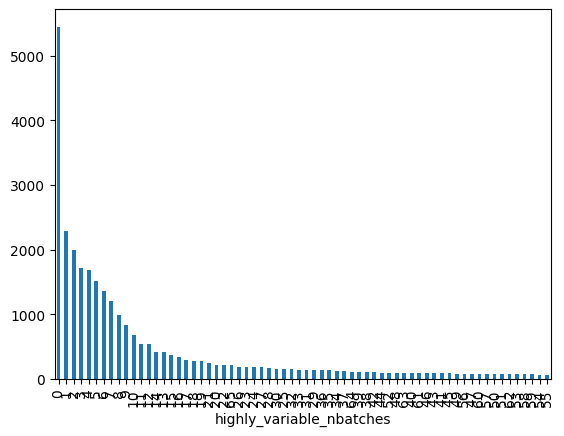

In [37]:
num_1_nbatches = hvg_combined_inter[hvg_combined_inter["highly_variable_nbatches"] >= 1].shape[0]
num_10_nbatches = hvg_combined_inter[hvg_combined_inter["highly_variable_nbatches"] >= 10].shape[0]
num_15_nbatches = hvg_combined_inter[hvg_combined_inter["highly_variable_nbatches"] >= 15].shape[0]
num_20_nbatches = hvg_combined_inter[hvg_combined_inter["highly_variable_nbatches"] >= 20].shape[0]
num_25_nbatches = hvg_combined_inter[hvg_combined_inter["highly_variable_nbatches"] >= 25].shape[0]
num_30_nbatches = hvg_combined_inter[hvg_combined_inter["highly_variable_nbatches"] >= 30].shape[0]

print("######## combined v2+v3 ########")
print(f"# of HVG: ", adata_tumor_full.var.highly_variable.sum())
print(f"# of Genes with >=1 nbatches: ", num_1_nbatches)
print(f"# of Genes with >=10 nbatches: ", num_10_nbatches)
print(f"# of Genes with >=15 nbatches: ", num_15_nbatches)
print(f"# of Genes with >=20 nbatches: ", num_20_nbatches)
print(f"# of Genes with >=25 nbatches: ", num_25_nbatches)
print(f"# of Genes with >=30 nbatches: ", num_30_nbatches)

n_batches = hvg_combined_inter["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

In [38]:
hvg_combined_inter["highly_variable_nbatches"].value_counts()[:25]

highly_variable_nbatches
0     5450
1     2290
2     1996
3     1712
4     1681
5     1514
6     1357
7     1202
8      994
9      836
10     671
11     542
12     533
14     417
13     414
15     371
16     335
17     296
18     276
19     274
21     241
20     221
22     210
65     208
26     189
Name: count, dtype: int64

## Comparison

### HVGs in full that we lose through intersection
Here we need to consider that the number of HVGs is already higher than the intersected ones. ~6400 vs 5000. Therefore we will obtain here a lot more missing HVGs from the transfer from full to intersection.

To combat that with the analysis from above we can use the HVG in combination with the nbatches to only take a look at genes that are actually highly variable in a at least a single batch. The full tumor data HVGs had the problem of always having a substantial amount of HVGs that are not highly variable in a single batch. 

In [44]:
adata_tumor_inter.var

,gene_symbol,gene_id,mt,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,highly_variable,highly_variable_rank,means,variances,variances_norm,highly_variable_nbatches
FAM138A,FAM138A,ENSG00000237613,False,0,0.000000,100.000000,0,False,NaN,0.000000,0.000000,0.000000,0
OR4F5,OR4F5,ENSG00000186092,False,1,0.000009,99.999075,1,False,NaN,0.000009,0.000009,0.015398,0
RP11-34P13.7,RP11-34P13.7,ENSG00000238009,False,673,0.006316,99.377607,683,False,4054.0,0.006316,0.006462,0.901300,3
RP11-34P13.8,RP11-34P13.8,ENSG00000239945,False,11,0.000102,99.989827,11,False,4918.0,0.000102,0.000102,0.137899,1
RP11-34P13.14,RP11-34P13.14,ENSG00000239906,False,0,0.000000,100.000000,0,False,NaN,0.000000,0.000000,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-ND4L,MT-ND4L,ENSG00000212907,True,86388,14.549084,20.108017,1573207,False,3044.0,14.549084,1586.499919,0.834912,10
MT-ND4,MT-ND4,ENSG00000198886,True,104871,486.782597,3.014862,52636289,False,3338.5,486.782597,593320.455334,0.790129,6
MT-ND5,MT-ND5,ENSG00000198786,True,98008,48.879997,9.361793,5285443,True,2375.0,48.879997,7512.667908,0.761492,6
MT-ND6,MT-ND6,ENSG00000198695,True,70867,4.184489,34.461903,452473,False,2931.0,4.184489,93.059601,0.921054,19


In [40]:
full_hvg = adata_tumor_full.var

# lost HVGs
full_hvg_strong = full_hvg[full_hvg["highly_variable"]]
lost_hvg = full_hvg_strong.index.difference(adata_tumor_inter.var_names)
hvg_lost_hvg = full_hvg_strong.index.difference(adata_tumor_inter.var[adata_tumor_inter.var["highly_variable"]].index)

In [47]:
print(f"# of all gene tumor HVGs that are not in intersection: {len(lost_hvg)}")
print(f"# of all gene tumor HVGs that are not in intersection HVG: {len(hvg_lost_hvg)}")
for gene in lost_hvg[:10]:
    print(gene)

# of all gene tumor HVGs that are not in intersection: 698
# of all gene tumor HVGs that are not in intersection **HVG**: 1622
ABALON
AC000403.4
AC003051.1
AC003102.3
AC004383.4
AC004754.3
AC004987.7
AC005027.4
AC005301.9
AC005921.2


Above we can see that through the intersection alone we lose about 700 genes that are considered highly variable in the full gene tumor dataset. If we expand that to the intersection HVG we lose ~1600 genes that are HVG in the complete gene tumor dataset but not present in the gene intersection tumor dataset.

An important caveat is that the HVG from the complete gene tumor dataset is already bigger with ~6.3k HVGs compared to the gene intersection HVG count of exactly 5k.

### Lost genes from highly_variable_genes with high nbatches count 

# Intersection final selection

In [50]:
# already computed top 5k HVG
adata_tumor_inter

AnnData object with n_obs × n_vars = 108131 × 28617
    obs: 'cell_id', 'donor_id', 'biosample_id', 'mmr_status', 'chemistry', 'batch', 'label', 'cell_type', 'mlh1_status', 'sex', 'tissue_site', 'pathological_stage', 'tumor_grade', 'c_value', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'outlier_qc', 'n_genes', 'doublet_score', 'predicted_doublet', 'outlier'
    var: 'gene_symbol', 'gene_id', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'hvg'
    layers: 'counts'

In [59]:
# already computed top 5k HVG
adata_CL_inter

AnnData object with n_obs × n_vars = 2162 × 28617
    obs: 'cell_id', 'pool_id', 'cell_line', 'mmr_status', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'outlier_qc', 'n_genes', 'doublet_score', 'predicted_doublet', 'outlier', 'chemistry'
    var: 'gene_symbol', 'gene_id', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: 'counts'

In [58]:
remove_vars = [
    "highly_variable", "highly_variable_rank", "means",
    "variances", "variances_norm", "highly_variable_nbatches",
]

adata_CL_inter.var = adata_CL_inter.var.drop(columns=remove_vars)
adata_CL_inter.uns.pop("hvg") # remove hvg flavor in uns dict

KeyError: "['highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'] not found in axis"

In [60]:
sc.pp.highly_variable_genes(
    adata_CL_inter,
    n_top_genes=2000,
    subset=False,
    layer="counts",
    flavor="seurat_v3",
    batch_key="pool_id"
)

highly_variable_nbatches
0    21158
1     4642
2     1757
3      619
4      266
5      127
6       48
Name: count, dtype: int64

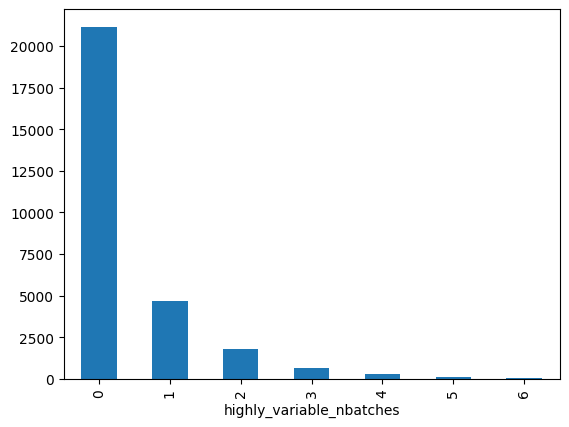

In [62]:
n_batches = adata_CL_inter.var["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

highly_variable_nbatches
1    1213
2     339
3     194
4     127
5      88
6      39
Name: count, dtype: int64

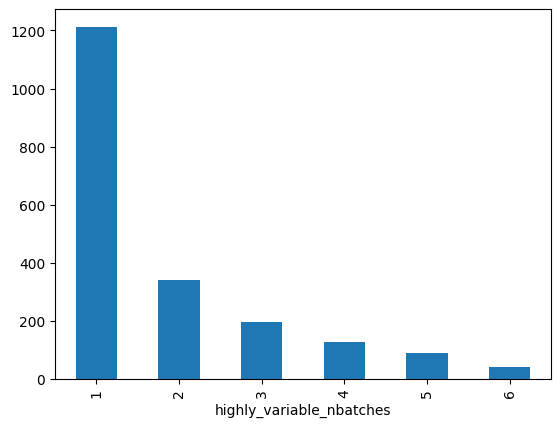

In [66]:
n_batches = adata_CL_inter.var[adata_CL_inter.var["highly_variable"]]["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

In [89]:
hvg_2k_CL = adata_CL_inter.var[adata_CL_inter.var["highly_variable"]]
hvg_tumor_inter = adata_tumor_inter.var[adata_tumor_inter.var["highly_variable"]]
print(f"Shape cell line intersection HVG: {hvg_2k_CL.shape[0]}")
print(f"Shape tumor intersection HVG: {hvg_tumor_inter.shape[0]}")

Shape cell line intersection HVG: 2000
Shape tumor intersection HVG: 5000


In [92]:
hvg_2k_CL.index.isin(hvg_tumor_inter.index).sum()

np.int64(914)

In [98]:
hvg_tumor_inter_v2 = adata_tumor_inter_v2.var[adata_tumor_inter_v2.var["highly_variable"]]
hvg_2k_CL.index.isin(hvg_tumor_inter_v2.index).sum()

np.int64(951)

In [100]:
hvg_2k_CL.index.isin(hvg_tumor_inter_v2.index).sum()

np.int64(951)